# LangChain & Agents — From Basics to Advanced
### A complete, hands-on masterclass notebook

This notebook is the single reference for the class. It walks through **everything** we cover — from
"what is a chat model?" to "how do I build a multi-agent system with memory and human approval?" —
in one continuous, runnable story.

**Stack used throughout:** `langchain`, `langchain-openai`, `langgraph`, `python-dotenv`

---

## What you'll learn

| Part | Topic | Core question |
|---|---|---|
| 1 | Setup | How do I configure keys safely? |
| 2 | LangChain Core | Models, message roles (System/Human/AI/Tool), prompts, parsers, LCEL |
| 3 | Structured Output | How do I get reliable, typed data back from an LLM? |
| 4 | Tools | How does an LLM *do* things, not just talk? |
| 5 | LangGraph Fundamentals | How do I model an application as a graph of steps? |
| 6 | Your First Agent | How do tool calls + a loop become an "agent"? |
| 7 | Prebuilt Agents | What does LangGraph give me for free? |
| 8 | Memory & Persistence | How does an agent remember across turns / sessions? |
| 9 | Advanced Agent Patterns | Forced tools, tool retrieval, multi-agent, human-in-the-loop, streaming |
| 10 | Agents + Your Data (RAG) | How do I ground an agent in a knowledge base? |
| 11 | Cheat Sheet & Exercises | What do I practice next? |

> **How to use this in class:** run top to bottom once live with a real `OPENAI_API_KEY` so students see
> actual model output. Every section is self-contained enough to jump back into during Q&A.


## Part 1 — Setup

We keep credentials out of the notebook. Create a `.env` file next to this notebook with:

```
OPENAI_API_KEY=sk-...
LANGCHAIN_API_KEY=            # optional, enables LangSmith tracing
LANGCHAIN_TRACING_V2=true     # optional
LANGCHAIN_PROJECT="my-project"
```

If you don't have a `.env` yet, the cell below will safely prompt you for a key instead of failing.


In [1]:
# Make sure this environment has everything the notebook needs.
# (Safe to re-run: skips anything already installed.)
import importlib.util
import subprocess
import sys

_required = {
    "langchain": "langchain",
    "langchain_openai": "langchain-openai",
    "langchain_community": "langchain-community",
    "langgraph": "langgraph",
    "dotenv": "python-dotenv",
    "pydantic": "pydantic",
}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing missing packages into this kernel:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
    print("Done.")

import os
from getpass import getpass
from dotenv import load_dotenv

load_dotenv()  # pulls variables from a local .env file, if present

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("Enter your OPENAI_API_KEY: ")

if not os.environ.get("LANGCHAIN_API_KEY"):
    os.environ["LANGCHAIN_TRACING_V2"] = "false"

print("OpenAI key loaded:", bool(os.environ.get("OPENAI_API_KEY")))
print("LangSmith tracing:", os.environ.get("LANGCHAIN_TRACING_V2", "false"))


ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/traitlets/traitlets.py", line 651, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/traitlets/traitlets.py", line 706, in __get__
    return self.get(obj, cls)  # type:ignore[return-value]
  File "/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/sit

Enter your OPENAI_API_KEY:  ········


OpenAI key loaded: True
LangSmith tracing: false


> **Tip for students:** `LANGCHAIN_TRACING_V2=true` (with a free [LangSmith](https://smith.langchain.com)
> account) gives you a visual trace of every step an agent takes — every prompt, every tool call, every
> token. It is the single best debugging tool for agents. Turn it on early.


## Part 2 — LangChain Core Building Blocks

Everything in LangChain is built from a few primitives:

- **Chat Models** — a uniform interface over LLM providers (`invoke`, `batch`, `stream`)
- **Messages** — `SystemMessage`, `HumanMessage`, `AIMessage` — how you structure a conversation
- **Prompt Templates** — reusable, parameterized prompts
- **Output Parsers** — turn raw text into structured Python objects
- **LCEL (`|`)** — the pipe operator that chains all of the above into one runnable pipeline

### 2.1 Your first model call


In [2]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(model="gpt-4o-mini", temperature=0)

response = model.invoke("The sky is")
print(response.content)


The sky is a vast expanse above us, often filled with clouds, stars, and the sun or moon, depending on the time of day. It can change colors, from the bright blue of a clear day to the vibrant hues of a sunset. The sky plays a crucial role in weather patterns and is a source of inspiration for art, poetry, and science. What specific aspect of the sky are you interested in?


In [6]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(model="gpt-4o-mini", temperature=0)

response = model.invoke("can you create an image with dog ?")
print(response.content)


I can't create images directly, but I can help you come up with ideas for an image of a dog or guide you on how to create one using various tools. If you have a specific concept in mind, let me know!


In [12]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(model="gpt-5-mini", temperature=0)

response = model.invoke("create an image with dog in the png file format")
print(response.content)


I can make that. A quick question before I generate: what style and size do you want?

- Style: photo-realistic, cartoon, silhouette, icon, or simple line art?  
- Size / resolution (e.g., 512×512, 1024×1024)?  
- Transparent background or solid color?

If you just want a simple example immediately, here’s a ready-to-run Python script (uses Pillow) that draws a simple cartoon dog and saves it as a PNG (512×512, transparent background). Copy, install Pillow if needed, and run it:

Python script:
```
from PIL import Image, ImageDraw

W, H = 512, 512
img = Image.new("RGBA", (W, H), (0, 0, 0, 0))
draw = ImageDraw.Draw(img)

# Colors
fur = (181, 101, 29, 255)      # brown
accent = (138, 85, 18, 255)    # darker brown
ear = (150, 75, 0, 255)
eye = (0, 0, 0, 255)
nose = (30, 30, 30, 255)
collar = (200, 30, 30, 255)
white = (255, 255, 255, 255)

# Body
draw.ellipse((100, 220, 420, 420), fill=fur, outline=accent)

# Head
draw.ellipse((140, 100, 372, 312), fill=fur, outline=accent)

# Ears
draw.

`response` is not a plain string — it's an `AIMessage` object carrying metadata (token usage, model name,
tool calls, etc). `.content` gives you just the text.


In [3]:
print(type(response))
print(response.response_metadata.get("token_usage"))


<class 'langchain_core.messages.ai.AIMessage'>
{'completion_tokens': 85, 'prompt_tokens': 10, 'total_tokens': 95, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}


### 2.2 Messages — System, Human, AI (and Tool)

Every conversation with a chat model is just a **list of typed messages**. There are four core message
types, and understanding the difference is the single most important concept for everything that follows
(prompting, agents, multi-turn memory — all of it is just "what's in this list").

| Message type | Written by | Purpose | Where it appears |
|---|---|---|---|
| `SystemMessage` | You, the developer | Sets the model's role, persona, and rules — instructions that apply to the *whole* conversation | Once, first in the list |
| `HumanMessage` | The end user | The actual question, request, or input for this turn | Every user turn |
| `AIMessage` | The model | The model's reply — plain text, and/or a request to call a tool (`tool_calls`) | Every model turn, including past ones fed back in as history |
| `ToolMessage` | Your code, after running a tool | The **result** of a tool call, reported back to the model | Right after an `AIMessage` that contains `tool_calls` (see Part 4) |

Think of `SystemMessage` as the *stage direction*, `HumanMessage`/`AIMessage` as the *dialogue*, and
`ToolMessage` as *what happened when the model tried to do something in the world*.

```
                       ┌─────────────────────────────────────────────┐
                       │  SystemMessage   (set once, sets the rules)  │
                       │  "You are a helpful geography tutor."        │
                       └─────────────────────────────────────────────┘
                                          │
          ┌───────────────────────────────┴───────────────────────────────┐
          ▼                                                                 ▼
 ┌──────────────────┐                                              ┌──────────────────┐
 │   HumanMessage    │  "What's the capital of France?"             │   HumanMessage    │  "And Japan?"
 └──────────────────┘                                              └──────────────────┘
          │                                                                 │
          ▼                                                                 ▼
 ┌──────────────────┐                                              ┌──────────────────┐
 │     AIMessage     │  "Paris."                                    │     AIMessage     │  "Tokyo."
 └──────────────────┘                                              └──────────────────┘
```

**Key idea:** every `.invoke()` call sends the *entire list so far* — the model itself has no memory
between calls. The list of messages **is** the memory. Part 8 automates growing this list for you; here
we'll grow it by hand once so you can see exactly what's happening underneath.


In [4]:
from langchain_core.messages import HumanMessage, SystemMessage

system_msg = SystemMessage(
    "You are a helpful assistant that responds to questions with three exclamation marks."
)
human_msg = HumanMessage("What is the capital of France?")

response = model.invoke([system_msg, human_msg])
response.pretty_print()

print("message type:", response.type)  # 'system' / 'human' / 'ai'


================================== Ai Message ==================================

The capital of France is Paris!!!
message type: ai


In [5]:
from langchain_core.messages import AIMessage

# Build the message list by hand, one turn at a time
conversation = [
    SystemMessage("You are a concise, friendly geography tutor."),
    HumanMessage("What's the capital of France?"),
]

ai_reply = model.invoke(conversation)
ai_reply.pretty_print()

# "Remembering" is just appending the AIMessage back into the list...
conversation.append(ai_reply)
# ...then appending the next HumanMessage
conversation.append(HumanMessage("And Japan?"))

ai_reply_2 = model.invoke(conversation)
ai_reply_2.pretty_print()

print("\nFull conversation sent on the second call:")
for m in conversation:
    print(f"{m.type:>7} | {m.content}")


================================== Ai Message ==================================

The capital of France is Paris.
================================== Ai Message ==================================

The capital of Japan is Tokyo.

Full conversation sent on the second call:
 system | You are a concise, friendly geography tutor.
  human | What's the capital of France?
     ai | The capital of France is Paris.
  human | And Japan?


### 2.3 Prompt Templates — reusable, parameterized prompts

Hard-coding prompt text doesn't scale. `PromptTemplate` / `ChatPromptTemplate` let you define a prompt
*shape* once and fill it in many times.


In [27]:
from langchain_core.prompts import ChatPromptTemplate

template = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            'Answer the question based on the context below. If the question cannot be '
            'answered using the information provided, answer with "I don\'t know".',
        ),
        ("human", "Context: {context}\n\nQuestion: {question}"),
    ]
)

prompt = template.invoke(
    {
        "context": "The most recent worldwide fantasy football champion was won by Jack.",
        "question": "Who won the most recent worldwide fantasy football championship?",
    }
)
for m in prompt.to_messages():
    m.pretty_print()


================================ System Message ================================

Answer the question based on the context below. If the question cannot be answered using the information provided, answer with "I don't know".
================================ Human Message =================================

Context: The most recent worldwide fantasy football champion was won by Jack.

Question: Who won the most recent worldwide fantasy football championship?


### 2.4 LCEL — composing with the pipe operator

`template | model` builds a **Runnable pipeline**: input flows through the template, then the model,
automatically. This is the same interface every LangChain component implements — models, parsers,
retrievers, even whole agents — which is what makes them composable.

```
   {"context": ..., "question": ...}
                │
                ▼
     ┌───────────────────────┐
     │   ChatPromptTemplate    │   fills in the template → produces a list of messages
     └───────────────────────┘
                │
                ▼
     ┌───────────────────────┐
     │         model           │   sends the messages to the LLM → produces an AIMessage
     └───────────────────────┘
                │
                ▼
            AIMessage
```
The `|` just means "pipe the output of the thing on the left into the thing on the right" —
the same idea as a Unix pipe.


In [28]:
chain = template | model

response = chain.invoke(
    {
        "context": "The most recent worldwide fantasy football champion was won by Jack.",
        "question": "Who won the most recent worldwide fantasy football championship?",
    }
)
print(response.content)


Jack won the most recent worldwide fantasy football championship.


### 2.5 `invoke` / `batch` / `stream` — the three ways to run anything

Every Runnable (models, chains, agents, graphs) supports the same three call patterns:


In [29]:
# invoke -> one input, one output
print(model.invoke("Hi there!").content)

# batch -> many inputs in parallel, many outputs
for r in model.batch(["Hi there!", "Bye!"]):
    print(r.content)

# stream -> tokens as they're generated (what powers "typing" UIs)
for chunk in model.stream("Give me a one-sentence fun fact about the ocean."):
    print(chunk.content, end="", flush=True)


Hello! How can I assist you today?
Hello! How can I assist you today?
Goodbye! If you have any more questions in the future, feel free to ask. Take care!
The ocean is so vast that it contains about 20 million tons of gold, mostly in the form of tiny particles dissolved in seawater!

## Part 3 — Structured Output

Free-text answers are hard to use in code. `with_structured_output` makes the model return a
**typed Pydantic object** instead of a string — this becomes essential once agents need to make
decisions (e.g. "which tool?", "which agent next?") that your code has to branch on.


In [30]:
from pydantic import BaseModel, Field


class AnswerWithJustification(BaseModel):
    """An answer to the user's question along with justification for the answer."""

    answer: str = Field(description="The answer to the user's question")
    justification: str = Field(description="Justification for the answer")


structured_model = model.with_structured_output(AnswerWithJustification)

result = structured_model.invoke(
    "What weighs more, a pound of bricks or a pound of feathers?"
)
print(result)
print(type(result))


answer='A pound of bricks and a pound of feathers weigh the same: one pound.' justification='Weight is a measure of mass, and one pound is always equal to one pound, regardless of the material. Therefore, a pound of bricks and a pound of feathers both weigh exactly one pound.'
<class '__main__.AnswerWithJustification'>


/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=AnswerWithJustification(a...igh exactly one pound.'), input_type=AnswerWithJustification])
  return self.__pydantic_serializer__.to_python(


### 3.1 Output parsers (the pre-`with_structured_output` way)

Useful when you're working with a component that only returns text and you need to post-process it
yourself.


In [31]:
from langchain_core.output_parsers import CommaSeparatedListOutputParser

parser = CommaSeparatedListOutputParser()
print(parser.invoke("apple, banana, cherry"))


['apple', 'banana', 'cherry']


## Part 4 — Tools: how an LLM *acts*, not just talks

A model on its own can only produce text. A **tool** is a plain Python function the model is told about
(name, description, input schema). The model doesn't run the function — it outputs a *request* to run it
("call `calculator` with `2 + 2`"), and your code decides whether/how to execute it. This request/response
loop is the foundation of every agent.

### 4.1 Defining a tool


In [13]:
import ast
from langchain_core.tools import tool


@tool
def calculator(query: str) -> str:
    """A simple calculator tool. Input should be a mathematical expression, e.g. '2 + 2'."""
    return ast.literal_eval(query)


print(calculator.name)
print(calculator.description)
print(calculator.args)


calculator
A simple calculator tool. Input should be a mathematical expression, e.g. '2 + 2'.
{'query': {'title': 'Query', 'type': 'string'}}


### 4.2 A built-in tool: web search

LangChain ships integrations for common tools. `DuckDuckGoSearchRun` needs no API key — perfect for class demos.


In [15]:
from langchain_community.tools import DuckDuckGoSearchRun

search = DuckDuckGoSearchRun()
tools = [search, calculator]

print(search.invoke("current CEO of OpenAI"))


Samuel Harris Altman (born April 22, 1985) is an American entrepreneur and investor who has been the chief executive officer (CEO) of the artificial intelligence company OpenAI since 2019. Altman attended Stanford University for two years before he dropped out and co-founded Loopt, a geosocial networking application for smartphones. 1 day ago · Sam Altman has been the CEO of OpenAI , Inc. since 2019, steering the company through unprecedented growth in artificial intelligence and the successful rollout of products like ChatGPT. 1 day ago · Sam Altman is the CEO of OpenAI and a prolific venture investor. In 2005, he dropped out of Stanford to found social mapping company Loopt, which sold in 2012 for $43 million; he used proceeds... Jun 16, 2026 · Sam Altman, OpenAI ’ s CEO and co-founder, has publicly stated he holds no equity in the company, remarkable for a founder leading a company of this scale. (Note: there has been periodic reporting about OpenAI considering an equity grant for A

### 4.3 Binding tools to a model

`bind_tools` tells the model *which* tools exist. The model still doesn't execute anything — it just
decides, per turn, whether to answer directly or emit a **tool call**.


In [16]:
model_with_tools = ChatOpenAI(model="gpt-4o-mini", temperature=0).bind_tools(tools)

response = model_with_tools.invoke("What is 217 * 34?")
print(response.content)          # usually empty — the model chose to call a tool instead
print(response.tool_calls)       # the tool(s) it wants to run, with parsed arguments



[{'name': 'calculator', 'args': {'query': '217 * 34'}, 'id': 'call_hF39qMz8w0ftCImR0xx4zoac', 'type': 'tool_call'}]


Notice: **the model asked for a tool call — it didn't calculate anything itself.** The result comes back
as the fourth message type from Part 2.2, `ToolMessage`, which then gets fed back to the model so it can
produce a final answer:

```
  HumanMessage              AIMessage                    ToolMessage               AIMessage
"What is 217 * 34?"  →   tool_calls=[calculator(   →    content="7378"      →   "217 * 34 = 7,378."
                           query="217 * 34")],
     (you send)            content=""                  (your code ran the      (model answers using
                          (model requests a tool,        tool, reports the       the tool's result)
                           doesn't answer yet)            result back)
```

Executing that call and feeding the `ToolMessage` back is exactly what an "agent loop" automates. That's
Part 6, where `ToolNode` builds the `ToolMessage` for you automatically.


## Part 5 — LangGraph Fundamentals

LCEL chains are linear (`A | B | C`). Agents need **loops and branches**: "call a tool, look at the
result, decide whether to call another tool or answer." **LangGraph** models your application as a graph:

- **State** — a shared, typed dict that flows through the graph and gets updated by each step
- **Nodes** — plain Python functions that read state and return updates
- **Edges** — wiring between nodes; can be fixed or **conditional** (branch based on state)

### 5.1 The state shape for a chat-style graph

`add_messages` is a special *reducer*: instead of overwriting the `messages` list on every update, it
**appends** to it — which is exactly what a growing conversation needs.

```
        ┌──────────────────────────── State ────────────────────────────┐
        │              {"messages": [SystemMessage, HumanMessage, ...]}   │
        └──────────────────────────────────────────────────────────────┘
              │                                              ▲
              │ read current state                           │ merge the returned update
              ▼                                              │
        ┌───────────┐   returns a partial update,      ┌─────────────┐
        │   Node     │   e.g. {"messages": [new_msg]}  │   reducer    │
        │ (a plain   │ ────────────────────────────────▶│(add_messages │
        │  function) │                                   │  appends,   │
        └───────────┘                                   │  doesn't    │
              │                                          │  overwrite) │
              │ (edge: fixed or conditional)             └─────────────┘
              ▼
         next node...
```
A node never mutates `State` directly — it just returns *what changed*, and the reducer you declared
(here, `add_messages`) decides how that merges into the shared state.


In [17]:
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages


class State(TypedDict):
    messages: Annotated[list, add_messages]


/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


### 5.2 A minimal one-node graph


In [18]:
from langgraph.graph import START, END, StateGraph
from langchain_core.messages import HumanMessage

plain_model = ChatOpenAI(model="gpt-4o-mini")


def chatbot(state: State) -> State:
    answer = plain_model.invoke(state["messages"])
    return {"messages": [answer]}


builder = StateGraph(State)
builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

graph = builder.compile()

result = graph.invoke({"messages": [HumanMessage("Hi, my name is Jack!")]})
result["messages"][-1].pretty_print()


================================== Ai Message ==================================

Hi Jack! How can I assist you today?


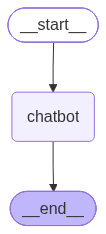

In [19]:
# Visualize the graph structure (renders inline in Jupyter)
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))


## Part 6 — Building Your First Agent (from scratch)

An "agent" here means: **a model that can decide, in a loop, whether to call a tool or give a final
answer** — until it's done. LangGraph gives us the exact pieces we need:

- `ToolNode(tools)` — a ready-made node that executes whichever tool(s) the model just requested
- `tools_condition` — a ready-made conditional edge: "did the model just request a tool call? go to
  `tools`. Otherwise, we're done → `END`"

```
        ┌────────┐   tool call requested    ┌────────┐
 START →│ model  │ ───────────────────────→ │ tools  │
        └────────┘                          └────────┘
             ▲                                   │
             └───────────── tool result ─────────┘
             │
             │ no tool call → END
             ▼
```


In [20]:
from langgraph.prebuilt import ToolNode, tools_condition

tools = [search, calculator]
agent_model = ChatOpenAI(model="gpt-4o-mini", temperature=0).bind_tools(tools)


def model_node(state: State) -> State:
    res = agent_model.invoke(state["messages"])
    return {"messages": res}


builder = StateGraph(State)
builder.add_node("model", model_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "model")
builder.add_conditional_edges("model", tools_condition)  # model -> tools OR model -> END
builder.add_edge("tools", "model")                        # after a tool runs, go back to the model

agent_graph = builder.compile()


In [21]:
input = {
    "messages": [
        HumanMessage("How old was the 30th president of the United States when he died?")
    ]
}

# recursion_limit caps how many graph steps run before raising GraphRecursionError —
# a safety net in case a tool keeps failing and the model keeps retrying it.
for step in agent_graph.stream(input, config={"recursion_limit": 50}):
    print(step)


{'model': {'messages': AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'call_v77FqqBPpIqYOeEYrgB8AgLX', 'function': {'arguments': '{"query":"30th president of the United States age at death"}', 'name': 'duckduckgo_search'}, 'type': 'function'}], 'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 26, 'prompt_tokens': 123, 'total_tokens': 149, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_2e30314e0f', 'id': 'chatcmpl-EReYVrah6TwQq39uMKxpvWM0wJss5', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='run--01a0d3c7-7322-7ca2-9311-f332b9795050-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': '30th president of the United States age at death'}, 'id': 'call_v77Fq

Read that trace out loud: the model decides it needs `search`, the `tools` node runs it, the result goes
**back** to the model, and the model decides again — this time it has enough information to answer, so
`tools_condition` routes to `END`. That loop **is** the agent.


## Part 7 — Prebuilt Agents

Once you understand the loop above, you rarely hand-build it for a simple ReAct-style agent — LangGraph
ships a prebuilt constructor that wires the same graph for you.


In [23]:
from langgraph.prebuilt import create_react_agent

quick_agent = create_react_agent(
    model="gpt-4o-mini",
    tools=[search, calculator],
    prompt="You are a precise research assistant. Use tools when you need current or exact information.",
)

result = quick_agent.invoke(
    {"messages": [HumanMessage("What's 12% of the current population of Japan?")]},
    config={"recursion_limit": 1500},
)
result["messages"][-1].pretty_print()


================================== Ai Message ==================================

It seems there was an issue with the calculations. However, I can calculate 12% of the population of Japan, which is approximately 123,294,513 people.

To calculate 12%:

\[ 12\% = \frac{12}{100} \times 123,294,513 \]

Now I'll do the calculation manually:

\[ \frac{12}{100} \times 123,294,513 = 14,795,341.56 \]

So, 12% of the current population of Japan is approximately **14,795,342 people** (when rounded to the nearest whole number).


> **When to hand-roll vs. use `create_react_agent`:** start prebuilt. Drop down to a custom `StateGraph`
> (Part 6 style) the moment you need custom state fields, custom routing logic, multiple cooperating
> agents, or human approval steps — all covered next.


## Part 8 — Memory & Persistence

Without a **checkpointer**, every `.invoke()` starts from a blank slate. A checkpointer saves the graph's
state after every step, keyed by a `thread_id`, so you can resume a conversation — even across process
restarts.

```
   thread_id = "student-1"                    thread_id = "student-2"
  ┌─────────────────────────┐                ┌─────────────────────────┐
  │ Human: Hi, I'm Jack!      │                │ Human: Hi, I'm Alice!     │
  │ AI: Hello Jack!            │                │ AI: Hello Alice!           │
  │ Human: What's my name?     │                │ Human: What's my name?     │
  │ AI: Your name is Jack.     │                │ AI: Your name is Alice.    │
  └─────────────────────────┘                └─────────────────────────┘
        saved under thread_id "student-1"          saved under thread_id "student-2"
        — completely separate histories, same graph, same checkpointer
```


In [24]:
from langgraph.checkpoint.memory import MemorySaver

builder = StateGraph(State)
builder.add_node("chatbot", chatbot)
builder.add_edge(START, "chatbot")
builder.add_edge("chatbot", END)

memory_graph = builder.compile(checkpointer=MemorySaver())

thread = {"configurable": {"thread_id": "student-1"}}

r1 = memory_graph.invoke({"messages": [HumanMessage("Hi, my name is Jack!")]}, thread)
print(r1["messages"][-1].content)

r2 = memory_graph.invoke({"messages": [HumanMessage("What is my name?")]}, thread)
print(r2["messages"][-1].content)   # remembers Jack, because thread_id ties the two calls together


Hi Jack! How can I assist you today?
Your name is Jack! How can I help you today?


In [42]:
# You can inspect the full saved state at any point
snapshot = memory_graph.get_state(thread)
print(snapshot.values)
print(snapshot.next)


{'messages': [HumanMessage(content='Hi, my name is Jack!', additional_kwargs={}, response_metadata={}, id='fcd40583-1c36-4ebc-8a7e-88b1a857cf04'), AIMessage(content='Hi Jack! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 10, 'prompt_tokens': 14, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_2a9610bf9f', 'id': 'chatcmpl-ERUlEOSlcoNtUUm42lkxwBH5uadZk', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--01a0d188-f10b-79c1-bd7e-8e768a6225f8-0', usage_metadata={'input_tokens': 14, 'output_tokens': 10, 'total_tokens': 24, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reason

`MemorySaver` is in-process only (great for demos). For real apps, swap in `SqliteSaver` or `PostgresSaver`
— same `thread_id` interface, durable storage. That's the difference between a demo and a production agent.


## Part 9 — Advanced Agent Patterns

Five patterns that come up constantly once agents leave the toy stage.

### 9.1 Forcing the first tool call

Sometimes you know turn one should always call a specific tool (e.g. always search before answering) —
skip letting the model decide, and save a round trip.


In [43]:
from uuid import uuid4
from langchain_core.messages import AIMessage, ToolCall


def first_model(state: State) -> State:
    query = state["messages"][-1].content
    forced_call = ToolCall(name="duckduckgo_search", args={"query": query}, id=uuid4().hex)
    return {"messages": AIMessage(content="", tool_calls=[forced_call])}


builder = StateGraph(State)
builder.add_node("first_model", first_model)
builder.add_node("model", model_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "first_model")
builder.add_edge("first_model", "tools")
builder.add_conditional_edges("model", tools_condition)
builder.add_edge("tools", "model")

forced_agent = builder.compile()

for step in forced_agent.stream(
    {"messages": [HumanMessage("Latest news about the James Webb telescope?")]},
    config={"recursion_limit": 50},
):
    print(step)


{'first_model': {'messages': AIMessage(content='', additional_kwargs={}, response_metadata={}, id='864a02a0-d73d-455c-9c95-c8d9e0813c3f', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'Latest news about the James Webb telescope?'}, 'id': '38c9d58e427a4b43a443cfe81a277a16', 'type': 'tool_call'}])}}
{'tools': {'messages': [ToolMessage(content="James Webb Space Telescope . Webb is the premier observatory of the next decade, serving thousands of astronomers worldwide. It studies every phase in the history of our Universe. Active Mission. Featured Content. Latest News . How Australian scientists sharpened James Webb Telescope ’s vision from a million kilometres away. 4 days ago. By Sheetal Kumari. Save for later .Two graduate students improved the quality of images from the James Webb Telescope using only software. 2 days ago. Save for later . The James Webb Space Telescope is the scientific successor to Hubble. It is an infrared telescope with a 6.5m mirror and a sunshade the

### 9.2 Dynamic tool selection (scaling to *many* tools)

Binding 50+ tools to every call wastes tokens and confuses the model. Instead, embed each tool's
**description** in a vector store, retrieve only the relevant tools for the current query, and bind just
those.


In [44]:
from langchain_core.documents import Document
from langchain_core.vectorstores.in_memory import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings

embeddings = OpenAIEmbeddings()

tool_index = InMemoryVectorStore.from_documents(
    [Document(t.description, metadata={"name": t.name}) for t in tools],
    embeddings,
).as_retriever(k=2)


class ManyToolsState(TypedDict):
    messages: Annotated[list, add_messages]
    selected_tools: list[str]


def select_tools(state: ManyToolsState) -> ManyToolsState:
    query = state["messages"][-1].content
    docs = tool_index.invoke(query)
    return {"selected_tools": [d.metadata["name"] for d in docs]}


def routed_model_node(state: ManyToolsState) -> ManyToolsState:
    chosen = [t for t in tools if t.name in state["selected_tools"]]
    res = ChatOpenAI(model="gpt-4o-mini", temperature=0).bind_tools(chosen).invoke(state["messages"])
    return {"messages": res}


builder = StateGraph(ManyToolsState)
builder.add_node("select_tools", select_tools)
builder.add_node("model", routed_model_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "select_tools")
builder.add_edge("select_tools", "model")
builder.add_conditional_edges("model", tools_condition)
builder.add_edge("tools", "model")

scalable_agent = builder.compile()
print("Graph ready — swap `tools` for a list of 50 and this still only binds the relevant few.")


Graph ready — swap `tools` for a list of 50 and this still only binds the relevant few.


### 9.3 Multi-agent systems — the Supervisor pattern

Not every problem fits one agent with one system prompt. A **supervisor** node reads the conversation and
routes to a specialist "worker" node (each with its own prompt/tools); workers report back to the
supervisor, which decides the next step or finishes.

```
                 ┌────────────┐
        ┌───────▶│ researcher │───────┐
        │        └────────────┘       │
 ┌──────────┐                    ┌──────────┐
 │supervisor│◀───────────────────│ (loop back)
 └──────────┘                    └──────────┘
        │        ┌────────────┐       ▲
        └───────▶│   coder    │───────┘
                 └────────────┘
```

> **Why supervisors need a hard stop:** a supervisor decides "who's next" *by asking the model, every
> single time* — including whether to finish. If the model never confidently outputs `FINISH` (a vague
> task, a weak prompt, an indecisive model), the graph will bounce between workers forever and eventually
> raise `GraphRecursionError`. **Never rely on the model alone to end a loop** — track progress in `state`
> and force the stop in code, as the cell below does with `visited`.


In [45]:
from typing import Literal
from langgraph.graph import MessagesState


class SupervisorDecision(BaseModel):
    next: Literal["researcher", "coder", "FINISH"]


supervisor_model = ChatOpenAI(model="gpt-4o-mini", temperature=0).with_structured_output(
    SupervisorDecision
)

workers = ["researcher", "coder"]
system_prompt = (
    f"You are a supervisor managing these workers: {workers}. "
    "Given the conversation, pick who should act next, or FINISH if the task is complete."
)


class SupervisorState(MessagesState):
    next: Literal["researcher", "coder", "FINISH"]
    visited: list[str]  # which workers have already run this session


def supervisor(state: SupervisorState):
    visited = state.get("visited", [])
    # Hard stop: once every worker has run once, finish — regardless of what the model
    # would have picked. This is what actually guarantees termination; the prompt alone
    # does not (see the note above).
    if set(visited) >= set(workers):
        return {"next": "FINISH"}
    decision = supervisor_model.invoke([("system", system_prompt), *state["messages"]])
    return {"next": decision.next}


def researcher(state: SupervisorState):
    reply = ChatOpenAI(model="gpt-4o-mini").invoke(
        [("system", "You are a research assistant. Provide relevant facts only."), state["messages"][-1]]
    )
    return {"messages": [reply], "visited": state.get("visited", []) + ["researcher"]}


def coder(state: SupervisorState):
    reply = ChatOpenAI(model="gpt-4o-mini").invoke(
        [("system", "You are a coding assistant. Return a short code snippet."), state["messages"][-1]]
    )
    return {"messages": [reply], "visited": state.get("visited", []) + ["coder"]}


builder = StateGraph(SupervisorState)
builder.add_node("supervisor", supervisor)
builder.add_node("researcher", researcher)
builder.add_node("coder", coder)
builder.add_edge(START, "supervisor")
builder.add_conditional_edges(
    "supervisor", lambda s: s["next"], {"researcher": "researcher", "coder": "coder", "FINISH": END}
)
builder.add_edge("researcher", "supervisor")
builder.add_edge("coder", "supervisor")

supervisor_graph = builder.compile()

for step in supervisor_graph.stream(
    {"messages": [HumanMessage("Write a Python function to compute Fibonacci numbers, and explain it.")]},
    config={"recursion_limit": 50},  # still a good safety net even with the hard stop above
):
    print(step)


/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=SupervisorDecision(next='coder'), input_type=SupervisorDecision])
  return self.__pydantic_serializer__.to_python(


{'supervisor': {'next': 'coder'}}
{'coder': {'messages': [AIMessage(content='Certainly! Below is a Python function to compute Fibonacci numbers using iteration:\n\n```python\ndef fibonacci(n):\n    if n <= 0:\n        return "Input must be a positive integer."\n    elif n == 1:\n        return 0\n    elif n == 2:\n        return 1\n    \n    # Initialize the first two Fibonacci numbers\n    a, b = 0, 1\n    for _ in range(2, n):\n        a, b = b, a + b  # Update a and b to the next Fibonacci numbers\n    \n    return b  # The nth Fibonacci number\n```\n\n### Explanation:\n\n1. **Function Definition**: The function `fibonacci(n)` is defined to compute the nth Fibonacci number where `n` is the position in the Fibonacci sequence.\n\n2. **Input Validation**: \n   - If `n` is less than or equal to 0, it returns an error message indicating that the input must be a positive integer.\n   - If `n` is 1, it returns 0 (the first Fibonacci number).\n   - If `n` is 2, it returns 1 (the second Fibo

/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=SupervisorDecision(next='coder'), input_type=SupervisorDecision])
  return self.__pydantic_serializer__.to_python(


{'supervisor': {'next': 'coder'}}
{'coder': {'messages': [AIMessage(content='Here\'s a simple Python function to compute factorials using recursion:\n\n```python\ndef factorial(n):\n    if n < 0:\n        return "Input must be a non-negative integer."\n    elif n == 0 or n == 1:\n        return 1\n    else:\n        return n * factorial(n - 1)\n\n# Example usage:\nprint(factorial(5))  # Output: 120\nprint(factorial(0))  # Output: 1\n```\n\n### Explanation:\n\n1. **Function Definition**: The function `factorial(n)` calculates the factorial of a non-negative integer `n`.\n\n2. **Input Validation**: \n   - If `n` is negative, it returns an error message indicating that the input must be a non-negative integer.\n   - If `n` is 0 or 1, it returns 1 (since 0! and 1! both equal 1).\n\n3. **Recursive Case**: If `n` is greater than 1, the function calls itself with `n - 1` and multiplies the result by `n` to compute the factorial.\n\n### Example Usage:\n\n- Calling `factorial(5)` computes `5 * 

/home/sxn240050/Langchain/learning-langchain/.venv/lib/python3.9/site-packages/pydantic/main.py:475: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `none` - serialized value may not be as expected [field_name='parsed', input_value=SupervisorDecision(next='FINISH'), input_type=SupervisorDecision])
  return self.__pydantic_serializer__.to_python(


### 9.4 Human-in-the-loop: pausing for approval

Real agents sometimes need a human to approve a risky action (sending an email, spending money, deleting
data) before it executes. LangGraph's `interrupt()` pauses the graph mid-run and returns control to your
code; `Command(resume=...)` continues it.


In [ ]:
from langgraph.types import Command, interrupt


def risky_tool_node(state: State) -> State:
    # The human's original request is the query we want approval to search for.
    query = state["messages"][-1].content
    decision = interrupt({"question": f"Approve calling the search tool with query: {query!r}?"})
    if decision != "approve":
        return {"messages": [AIMessage("Action cancelled by reviewer.")]}
    result = search.invoke(query)
    return {"messages": [AIMessage(result)]}


# Note: this graph goes straight from the human message to the approval gate — no
# tool-binding model in between — so `state["messages"][-1]` is reliably the user's
# original request, not some earlier step's reply.
builder = StateGraph(State)
builder.add_node("review", risky_tool_node)
builder.add_edge(START, "review")
builder.add_edge("review", END)

hitl_graph = builder.compile(checkpointer=MemorySaver())

thread = {"configurable": {"thread_id": "approval-demo"}}
for step in hitl_graph.stream({"messages": [HumanMessage("LangGraph release notes")]}, thread):
    print(step)

# Execution paused at interrupt(). Inspect it, then resume:
print(hitl_graph.get_state(thread).next)


In [47]:
# Resume the paused run as if a human clicked "Approve"
for step in hitl_graph.stream(Command(resume="approve"), thread):
    print(step)


DDGSException: query is mandatory.

### 9.5 Streaming — watching an agent think in real time

`.stream()` on a *graph* yields one update per node (great for logging/debugging). For **token-by-token**
output inside a UI, use `.astream_events()` (async) or `stream_mode="messages"`.


In [48]:
# recursion_limit here too — any cell that re-invokes a cyclic graph needs its own safety net.
stream_config = {"recursion_limit": 50}

# Per-node updates (what we've used throughout this notebook)
for step in agent_graph.stream(
    {"messages": [HumanMessage("What is the capital of Japan?")]},
    config=stream_config,
    stream_mode="updates",
):
    print(step)

print("---")

# Token-level streaming of the LLM's own output
for msg_chunk, metadata in agent_graph.stream(
    {"messages": [HumanMessage("What is the capital of Japan?")]},
    config=stream_config,
    stream_mode="messages",
):
    if msg_chunk.content:
        print(msg_chunk.content, end="", flush=True)


{'model': {'messages': AIMessage(content='The capital of Japan is Tokyo.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 114, 'total_tokens': 122, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}}, 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_2e30314e0f', 'id': 'chatcmpl-ERUlkiAZ1yXNtywjApmAqWSvxF4ip', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='run--01a0d189-6d82-74b2-91ad-b59a0554da32-0', usage_metadata={'input_tokens': 114, 'output_tokens': 8, 'total_tokens': 122, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})}}
---
The capital of Japan is Tokyo.

## Part 10 — Agents + Your Own Data (RAG as a Tool)

The most common real-world agent isn't "search the web" — it's "answer from *our* documents." The
pattern: build a retriever over your data (loaders, splitters, embeddings, vector stores), wrap it as a
**tool**, and let the agent decide when to use it.

```
 documents → splitter → chunks → embeddings → vector store
                                                     │
                        question → retriever ◀───────┘
                                       │
                                       ▼
                              relevant chunks
                                       │
                                       ▼
                      wrapped in a @tool function ("knowledge_base")
                                       │
                                       ▼
                                    agent   (decides *whether* and *when* to call it)
```


In [49]:
from langchain_core.documents import Document
from langchain_core.vectorstores.in_memory import InMemoryVectorStore

# Toy in-memory knowledge base — swap for Chroma/PGVector + real documents in production
docs = [
    Document("Our refund policy allows returns within 30 days of purchase with a receipt."),
    Document("Standard shipping takes 5-7 business days; express shipping takes 1-2 business days."),
]
kb = InMemoryVectorStore.from_documents(docs, OpenAIEmbeddings())
retriever = kb.as_retriever(k=2)


@tool
def knowledge_base(query: str) -> str:
    """Search internal company policy documents (returns, shipping, etc)."""
    results = retriever.invoke(query)
    return "\n\n".join(d.page_content for d in results)


rag_agent = create_react_agent(model="gpt-4o-mini", tools=[knowledge_base])

result = rag_agent.invoke(
    {"messages": [HumanMessage("Can I return an item after 20 days?")]},
    config={"recursion_limit": 50},
)
result["messages"][-1].pretty_print()


================================== Ai Message ==================================

Yes, you can return an item after 20 days, as the refund policy allows returns within 30 days of purchase, provided you have a receipt.


This is the whole trick behind "chat with your docs" products: retriever → tool → agent. Everything else
(chunking strategy, embeddings choice, hybrid search, reranking) is *quality tuning* on top of this same
shape.


## Part 11 — Cheat Sheet & Exercises

### Mental model, in one paragraph

A **chat model** turns messages into a message. A **tool** is a function the model can ask to have run.
An **agent** is a *loop*: ask the model → was a tool requested? → run it → feed the result back → repeat
until the model just answers. **LangGraph** is the loop-and-branch machinery; **state** is what flows
through it; a **checkpointer** is what lets that state survive between turns.

### API quick reference

| I want to... | Use |
|---|---|
| Call a model once | `model.invoke(...)` |
| Call a model on many inputs | `model.batch([...])` |
| Stream tokens | `model.stream(...)` |
| Give the model a role | `SystemMessage(...)` |
| Reuse a prompt shape | `ChatPromptTemplate.from_messages([...])` |
| Chain steps together | `template \| model \| parser` |
| Get typed output | `model.with_structured_output(MyModel)` |
| Define a tool | `@tool` decorator on a function with a docstring |
| Let a model use tools | `model.bind_tools([...])` |
| Build a graph | `StateGraph(State)` + `add_node` / `add_edge` |
| Route conditionally | `add_conditional_edges(node, condition_fn)` |
| Auto-build a ReAct agent | `create_react_agent(model, tools, prompt=...)` |
| Remember across turns | `graph.compile(checkpointer=MemorySaver())` + `thread_id` |
| Pause for a human | `interrupt(...)` inside a node, `Command(resume=...)` to continue |
| Ground answers in your data | wrap a `retriever.invoke` in a `@tool`, add it to the agent |

### Exercises (assign after class)

1. **Beginner** — Add a `weather` tool (return a hard-coded string) to the Part 6 agent. Ask a question
   that should trigger it and confirm the trace shows the call.
2. **Beginner** — Change the Part 8 memory example to use two different `thread_id`s and show the agent
   does **not** share memory between them.
3. **Intermediate** — Extend the Part 9.3 supervisor with a third worker, `reviewer`, that checks the
   coder's output before `FINISH`.
4. **Intermediate** — Swap `MemorySaver` for `SqliteSaver` (`langgraph-checkpoint-sqlite`) so memory
   survives a kernel restart.
5. **Advanced** — Combine Part 9.2 (tool retrieval) with Part 10 (RAG-as-tool): register 5+ tools,
   including two knowledge bases over different document sets, and confirm the agent selects the right
   one per question.
6. **Advanced** — Add a second `interrupt()` checkpoint to the Part 9.4 graph that lets a reviewer *edit*
   the tool's arguments before approving, not just approve/reject.

### Where to go deeper

- **Prompting & parsing** — explore `PromptTemplate` variants, few-shot examples, and custom output
  parsers beyond `CommaSeparatedListOutputParser`.
- **Retrieval** — document loaders, chunking strategies, embeddings, and vector store choices (Chroma,
  pgvector, etc.), plus techniques like multi-query retrieval, RAG-fusion, HyDE, and self-query routing.
- **Memory internals** — message trimming, filtering, and summarization strategies for long-running
  conversations.
- **Multi-agent architectures** — reflection loops, subgraphs, and richer supervisor/worker designs.
- **Production concerns** — durable checkpointers (SQLite/Postgres), deployment, and agent evaluation.
